<a href="https://colab.research.google.com/github/vzavala/DesignOfExperiments/blob/main/Python/ch5_hougen_watson_regularized.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Setup.** Run this cell first: it locates the data files this notebook reads. On Google
Colab it downloads them (the `Data/` and `Support/` folders) from the book's GitHub
repository; on your computer, run the notebook from the folder that contains `Data/`.

In [1]:
import os
import sys
path = ''
if 'google.colab' in sys.modules and not os.path.isdir('Data'):
    if not os.path.isdir('statsbook'):
        os.system('git clone -q --depth 1 --filter=blob:none --sparse '
                  'https://github.com/vzavala/DesignOfExperiments.git statsbook')
        os.system('git -C statsbook sparse-checkout set Python/Data Python/Support')
    path = 'statsbook/Python/'

Ridge-regularized SSE for the Hougen-Watson model (Victor Z and Leo Gonzalez, UW-Madison, 2024):

$$SSE(\theta)+\kappa\,\rho(\theta),\qquad \rho(\theta)=\frac{1}{2}\lVert\theta-\bar{\theta}\rVert_2^2,\quad \kappa=1,\ \bar{\theta}=0.$$

Python names: `kappa`, `theta_bar`, `rho(theta)`, `SSE(theta)` (model `m` as in `ch5_hougen_watson`).

**Note:** This notebook reproduces Example 5.12 (Section 5.4) of *Statistics for Chemical Engineers*: adding a ridge penalty to the SSE of the Hougen-Watson model.

**The concept.** A penalty keeps the parameters near a reference value $\bar{\theta}$. The ridge penalty is quadratic, so it adds $\kappa I$ to the Hessian:

$$\nabla_\theta\left[SSE+\kappa\rho\right]=-\mathcal{J}^T(\mathbf{y}-\mathbf{m}(\theta))+\kappa(\theta-\bar{\theta}),\qquad \mathcal{H}\approx\mathcal{J}^T\mathcal{J}+\kappa I.$$

Every eigenvalue increases by $\kappa$, so flat directions of $SSE$ gain curvature. In Bayesian terms, the penalty is a Gaussian prior $\theta\sim\mathcal{N}(\bar{\theta},(\sigma^2/\kappa)I)$.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

data = np.loadtxt(path+'Data/hougenwatson.dat')
X, y = data[:, :3], data[:, -1]

def m(theta, X):
    x1, x2, x3 = X[:, 0], X[:, 1], X[:, 2]
    return (theta[0]*x2 - x3/theta[4]) / (1 + theta[1]*x1 + theta[2]*x2 + theta[3]*x3)

def SSE(theta):
    return 0.5 * np.sum((y - m(theta, X))**2)

kappa = 1.0
theta_bar = np.zeros(5)

def rho(theta):
    return 0.5 * np.sum((theta - theta_bar)**2)

theta_ref = np.array([1.0, 0.05, 0.02, 0.1, 2.0])
grid = np.linspace(-2, 2, 201)
maps = {'SSE': np.zeros((201, 201)), 'regularized': np.zeros((201, 201))}
# the model has a pole where its denominator is zero; those grid points give SSE = inf (left blank in the plot)
with np.errstate(divide='ignore', invalid='ignore'):
    for i, t2 in enumerate(grid):
        for j, t1 in enumerate(grid):
            th = theta_ref.copy()
            th[1], th[2] = t1, t2
            maps['SSE'][i, j] = SSE(th)
            maps['regularized'][i, j] = SSE(th) + kappa * rho(th)

The two maps share the same grid, so the right one is the left one plus the paraboloid $\kappa\rho(\theta)$.

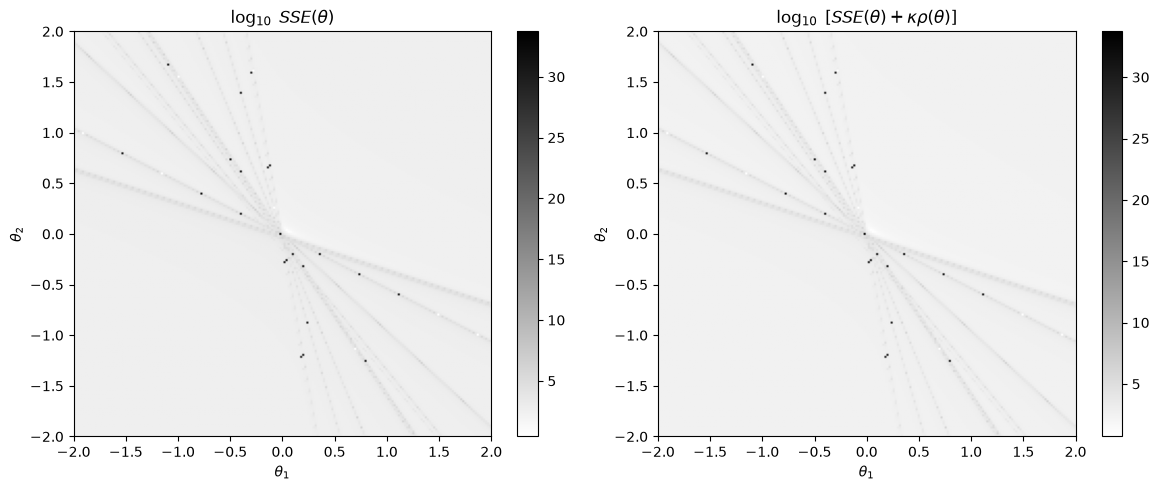

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for ax, (title, Z) in zip(axs, maps.items()):
    with np.errstate(divide='ignore'):
        logZ = np.log10(Z)
    im = ax.imshow(logZ, extent=[-2, 2, -2, 2], origin='lower', cmap='gray_r', aspect='auto')
    fig.colorbar(im, ax=ax)
    ax.set_title(r'$\log_{10}$ ' + ('$SSE(\\theta)$' if title == 'SSE' else r'$[SSE(\theta)+\kappa\rho(\theta)]$'))
    ax.set_xlabel(r'$\theta_1$'); ax.set_ylabel(r'$\theta_2$')
plt.tight_layout()
plt.show()

**The effect on the curvature.** Compute the eigenvalues of $\mathcal{J}^T\mathcal{J}$ and of $\mathcal{J}^T\mathcal{J}+\kappa I$ at the reference point, with $\mathcal{J}$ by finite differences.

In [4]:
h = 1e-6
J = np.column_stack([(m(theta_ref + h*e, X) - m(theta_ref - h*e, X)) / (2*h) for e in np.eye(5)])
np.set_printoptions(precision=3, suppress=False)
print("eigenvalues of J'J:          ", np.linalg.eigvalsh(J.T @ J))
print("eigenvalues of J'J + kappa I:", np.linalg.eigvalsh(J.T @ J + kappa * np.eye(5)))

eigenvalues of J'J:           [3.459e-02 1.526e+01 2.519e+03 2.070e+04 3.072e+05]
eigenvalues of J'J + kappa I: [1.035e+00 1.626e+01 2.520e+03 2.070e+04 3.072e+05]


**Note:** As in the book, the penalty makes the minimum sharper but does not remove the non-physical regions, so numerical issues may remain.